# 07 · 基线与线性探针（GreenPath）

**这一步做什么**：读取 06 提取并缓存的卫星图特征，在 05 冻结的数据集上训练一组由简单到复杂的模型，回答项目的核心问题——**"只看卫星图，能不能预测骑行体验？卫星图有没有提供 OSM 地图数据之外的信息？"**

| 编号 | 输入 | 方法 | 回答什么 |
|---|---|---|---|
| **B0** | 无 | 预测训练集均值 | 最低参照线，任何模型都应该比它好 |
| **B1** | OSM + WorldCover（约 30 列） | LightGBM，每个维度一个模型 | **强基线**：只靠地图数据能预测到什么程度 |
| **M1** | 卫星图 | 冻结的预训练编码器提特征 → 标准化 → Ridge 回归 | 预训练特征本身有多少信息（线性探针） |
| **M3** | 卫星图 + OSM | 图像特征 PCA 压缩后与 OSM 特征拼接 → LightGBM | **关键**：卫星图能否补充 OSM 没有的信息 |

M1 里试三个预训练编码器：**ResNet-50**（ImageNet）、**DINOv2 ViT-S/14**、**CLIP ViT-B/16**，按交叉验证选出最好的那个，再进入 M3。

| | 路径（相对数据根目录） |
|---|---|
| 输入：冻结的数据集 | `datasets/{版本}/dataset.parquet`、`schema.json` |
| 输入：卫星图特征（来自 06） | `embeddings/{版本}/{编码器}.parquet` |
| 输出：指标、预测、配置 | `results/{run_id}/…`，累计在 `results/metrics.parquet` |
| 输出：**实验日志** | `docs/EXPERIMENTS.md`（在项目目录里，每次运行追加一节） |

**评估方式（避免自欺欺人）**
- **选模型、选超参数只用交叉验证**：在 train+val 上按**空间区块分组的 5 折**，不碰测试集。编码器、正则强度 α、LightGBM 参数、PCA 维度，全部由 CV 分数自动选出，没有人工看测试集的环节。
- **测试集只在最后评估一次**：用全部 train+val 重新训练选定的模型，在测试集上算一次。
- **逐维度 Spearman**（排序是否一致，路线规划只关心相对高低）加 MAE；置信区间用**按区块的自助法**，因为同一区块里的格子不独立。
- 两个模型的差距（如 M3 − B1）也给置信区间：区间不含 0 才算真的更好。

**为什么特征要在单独的 notebook（06）里提取**：PyTorch 和 LightGBM 在 Mac 上不能放进同一个进程（两者各带一份 OpenMP 库，同时加载会崩溃）。所以提特征（只用 torch）和训练基线（只用 LightGBM / sklearn）分开，也对应以后的两个容器。

**注意**：标签是 Gemini 生成的，**尚未经人工验证**（E1）。这里所有的"准确"都是相对 Gemini 打分而言，不是相对真实的骑行体验。

## 1. 安装依赖（只在 Colab 里会执行）

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "lightgbm", "scikit-learn", "scipy", "tabulate", "pandas", "pyarrow", "gcsfs", "matplotlib", "tqdm", "fsspec"], check=True)

## 2. 配置
- `DATASET_VERSION`：用哪一版冻结的数据集。
- `BACKBONES`、`TTA`：用哪些编码器的特征、是否用了测试时增强。**要和 06 里提取时的设置一致**（决定读哪个缓存文件）。
- `RIDGE_ALPHAS`：Ridge 正则强度候选；`PCA_DIMS`：M3 里图像特征压缩到几维的候选；`LGB_GRID`：LightGBM 的候选参数。
- `N_BOOT`：自助法重采样次数（越大区间越准，越慢）。
- `RUN_NAME`：给这次实验起个名字，会写进实验日志。

In [2]:
DATASET_VERSION = "v1"
RUN_NAME = "baselines-first-run"

BACKBONES = ["resnet50", "dinov2_s", "clip_b16"]
TTA = True

RIDGE_ALPHAS = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]
PCA_DIMS = [16, 32, 64]
LGB_GRID = [dict(n_estimators=n, num_leaves=l) for n in (150, 400) for l in (7, 15)]
LGB_BASE = dict(learning_rate=0.05, min_child_samples=20, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, reg_lambda=1.0)
N_BOOT = 500
SEED = 42

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储，读入数据集

In [3]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [4]:
import numpy as np, time, os

# ⚠ 这个 notebook 里不要导入 torch：它和 LightGBM 各带一份 OpenMP 库，同一进程里同时加载会崩溃（macOS）。
# 图像特征由 06 单独提取并缓存。
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DIMS = ["traffic_intensity", "quietness", "shade", "naturalness",
        "scenic_appeal", "historic_character", "liveliness", "visual_openness"]
ds_dir = f"datasets/{DATASET_VERSION}"
ds = read_parquet(path(ds_dir, "dataset.parquet")).sort_values("cell_id").reset_index(drop=True)
with fs.open(path(ds_dir, "schema.json"), "r") as f:
    schema = json.load(f)

tab = ds[schema["tabular"]].astype("float32")
for c in schema["categorical"]:                                      # 类别特征（如 wc_dominant）→ 独立热编码
    tab = pd.concat([tab, pd.get_dummies(ds[c], prefix=c).astype("float32")], axis=1)
TAB = tab.values
Y = ds[DIMS].values.astype("float64")
pool = np.where(ds.split.isin(["train", "val"]))[0]                  # 选模型用
test = np.where(ds.split == "test")[0]                               # 只在最后看一次
fold = ds.fold.astype("float").values
block = ds.block_id.values
run_id = f"{RUN_NAME}-{datetime.datetime.utcnow().strftime('%Y%m%dT%H%M')}"
print(f"数据集 {DATASET_VERSION}：{len(ds)} 个格子 | 选模型用 {len(pool)}（5 折）| 测试 {len(test)}")
print(f"表格特征 {TAB.shape[1]} 列 | 标签 {len(DIMS)} 维 | run_id = {run_id}")

数据集 v1：1012 个格子 | 选模型用 824（5 折）| 测试 188
表格特征 32 列 | 标签 8 维 | run_id = baselines-first-run-20261013T0159


## 4. 读取卫星图特征（来自 06 的缓存）
**"基础模型"在这里的用法**：预训练编码器已经在海量图片上学会了"看图"，06 里把每张 224×224 的卫星图变成了一个特征向量（几百个数字），并缓存了下来。这里直接读取，**编码器不参与训练**（"冻结"），只有后面的回归头在学习。

In [5]:
EMB, EMB_META = {}, {}
for name in BACKBONES:
    rel = f"embeddings/{DATASET_VERSION}/{name}{'_tta' if TTA else ''}.parquet"
    if not fs.exists(path(rel)):
        raise FileNotFoundError(f"没找到 {rel}：请先运行 06_embeddings.ipynb 提取特征（BACKBONES 和 TTA 要和这里一致）")
    e = read_parquet(path(rel)).set_index("cell_id").reindex(ds.cell_id)
    assert not e.isna().any().any(), f"{name} 的特征缺少部分格子，请重新运行 06"
    EMB[name] = e.values.astype("float32")
    print(f"{name}: {EMB[name].shape}")
meta_path = path("embeddings", DATASET_VERSION, "meta.json")
if fs.exists(meta_path):
    with fs.open(meta_path, "r") as f:
        EMB_META = json.load(f)

resnet50: (1012, 2048)
dinov2_s: (1012, 384)
clip_b16: (1012, 512)


## 5. 评估工具
- `spearman_cols`：逐维度 Spearman。预测值完全不变（如 B0）时相关系数没有定义，记为 0。
- **按区块的自助法**：每次从区块里有放回地抽区块（同一区块的格子一起被抽中），而不是抽单个格子，因为同一区块的格子彼此很像，不独立；这样的置信区间才不会偏窄。
- 两个模型的比较用**同一批重采样**，所以差值的区间才有意义。

In [6]:
def spearman_cols(yt, yp):
    out = []
    for j in range(yt.shape[1]):
        ok = ~np.isnan(yt[:, j]) & ~np.isnan(yp[:, j])
        if ok.sum() < 5 or np.ptp(yp[ok, j]) == 0 or np.ptp(yt[ok, j]) == 0:
            out.append(0.0)
        else:
            out.append(spearmanr(yt[ok, j], yp[ok, j]).correlation)
    return np.array(out)

def mae_cols(yt, yp):
    return np.nanmean(np.abs(yt - yp), axis=0)

def block_resamples(groups, n, seed):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups); idx = {g: np.where(groups == g)[0] for g in ug}
    return [np.concatenate([idx[g] for g in rng.choice(ug, len(ug), replace=True)]) for _ in range(n)]

def boot(yt, yp, rs):
    return np.array([spearman_cols(yt[r], yp[r]) for r in rs])          # n_boot × 维度数

def ci(b):
    return np.nanpercentile(b, [2.5, 97.5], axis=0)

rs_cv = block_resamples(block[pool], N_BOOT, SEED)
rs_te = block_resamples(block[test], N_BOOT, SEED + 1)

## 6. 模型
四个"预测函数"，格式一致：`predict(训练行, 预测行, 参数) → 预测值`。交叉验证和最终测试都用它们，保证两处用的是同一套代码。
- 每个维度单独训练，只用该维度有标签的行（缺失标签不会被当成 0）；
- 预测值裁剪到 0–1，和标签范围一致；
- Ridge 和 PCA 的标准化只在训练行上拟合，不偷看验证行。

In [7]:
def p_b0(tr, te):
    return np.tile(np.nanmean(Y[tr], axis=0), (len(te), 1))

def p_b1(tr, te, P):
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = tr[~np.isnan(Y[tr, j])]
        m = lgb.LGBMRegressor(**LGB_BASE, **P, random_state=SEED, verbose=-1, n_jobs=4).fit(TAB[ok], Y[ok, j])
        out[:, j] = m.predict(TAB[te])
    return np.clip(out, 0, 1)

def p_m1(tr, te, name, alpha):
    E = EMB[name]; sc = StandardScaler().fit(E[tr]); Xtr, Xte = sc.transform(E[tr]), sc.transform(E[te])
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = ~np.isnan(Y[tr, j])
        out[:, j] = Ridge(alpha=alpha).fit(Xtr[ok], Y[tr][ok, j]).predict(Xte)
    return np.clip(out, 0, 1)

def p_m3(tr, te, name, P, k):
    E = EMB[name]; sc = StandardScaler().fit(E[tr]); pca = PCA(k, random_state=SEED).fit(sc.transform(E[tr]))
    Xtr = np.hstack([pca.transform(sc.transform(E[tr])), TAB[tr]]); Xte = np.hstack([pca.transform(sc.transform(E[te])), TAB[te]])
    out = np.zeros((len(te), len(DIMS)))
    for j in range(len(DIMS)):
        ok = ~np.isnan(Y[tr, j])
        m = lgb.LGBMRegressor(**LGB_BASE, **P, random_state=SEED, verbose=-1, n_jobs=4).fit(Xtr[ok], Y[tr][ok, j])
        out[:, j] = m.predict(Xte)
    return np.clip(out, 0, 1)

def run_cv(fn, **kw):
    # 按区块分好的 5 折：每折轮流当验证，其余当训练；返回所有 train+val 格子的"折外预测"
    oof = np.zeros((len(pool), len(DIMS))); pf = fold[pool]
    for k in np.unique(pf):
        te_pos, tr_pos = np.where(pf == k)[0], np.where(pf != k)[0]
        oof[te_pos] = fn(pool[tr_pos], pool[te_pos], **kw)
    return oof

cv_score = lambda oof: spearman_cols(Y[pool], oof).mean()          # 选模型用：8 个维度的平均 Spearman
PRED_CV, CHOSEN = {}, {}

## 7. B0 和 B1：不看图片的基线
**B1 是关键对照**：如果卫星图模型连「只看 OSM 表格」都赢不了，就说明卫星图没有提供额外价值。LightGBM 的参数用交叉验证从 `LGB_GRID` 里选。

In [8]:
t0 = time.time()
PRED_CV["B0"] = run_cv(p_b0)
rows = []
for P in LGB_GRID:
    oof = run_cv(p_b1, P=P); rows.append((P, cv_score(oof), oof))
rows.sort(key=lambda r: -r[1])
CHOSEN["B1"] = rows[0][0]; PRED_CV["B1"] = rows[0][2]
print(f"B1 候选（CV 平均 Spearman）：")
for P, s, _ in rows:
    print(f"  {P}  →  {s:.3f}" + ("   ← 选中" if P is CHOSEN["B1"] else ""))
print(f"B0 是常数预测，Spearman 按定义为 0（只看 MAE）| 用时 {time.time() - t0:.0f} 秒")

B1 候选（CV 平均 Spearman）：
  {'n_estimators': 150, 'num_leaves': 7}  →  0.573   ← 选中
  {'n_estimators': 150, 'num_leaves': 15}  →  0.568
  {'n_estimators': 400, 'num_leaves': 7}  →  0.561
  {'n_estimators': 400, 'num_leaves': 15}  →  0.557
B0 是常数预测，Spearman 按定义为 0（只看 MAE）| 用时 29 秒


## 8. M1：冻结编码器 + 线性回归头
对每个编码器，用交叉验证从 `RIDGE_ALPHAS` 里选最好的正则强度 α；再从三个编码器里选 CV 分数最高的，作为后面 M3 用的编码器。

In [9]:
t0 = time.time()
m1 = {}
for name in BACKBONES:
    best = None
    for a in RIDGE_ALPHAS:
        oof = run_cv(p_m1, name=name, alpha=a); s = cv_score(oof)
        if best is None or s > best[1]:
            best = (a, s, oof)
    m1[name] = best
    CHOSEN[f"M1_{name}"] = {"alpha": best[0]}; PRED_CV[f"M1_{name}"] = best[2]
res = pd.DataFrame({n: {"最佳 α": v[0], "CV 平均 Spearman": round(v[1], 3)} for n, v in m1.items()}).T
BEST_BB = max(m1, key=lambda n: m1[n][1])
CHOSEN["best_backbone"] = BEST_BB
print(res.to_string(), f"\n→ 选中编码器：{BEST_BB} | 用时 {time.time() - t0:.0f} 秒")

            最佳 α  CV 平均 Spearman
resnet50  3000.0           0.539
dinov2_s  1000.0           0.542
clip_b16  1000.0           0.548 
→ 选中编码器：clip_b16 | 用时 3 秒


## 9. M3：图像特征 + OSM 特征
用上面选出的编码器：先把图像特征标准化、PCA 压缩到 `k` 维，再和 OSM 特征拼成一张宽表，交给 LightGBM（参数用 B1 选出来的那组）。`k` 也由交叉验证选。

In [10]:
t0 = time.time()
best = None
for k in PCA_DIMS:
    oof = run_cv(p_m3, name=BEST_BB, P=CHOSEN["B1"], k=k); s = cv_score(oof)
    print(f"  PCA {k:>3} 维  →  CV 平均 Spearman {s:.3f}")
    if best is None or s > best[1]:
        best = (k, s, oof)
CHOSEN["M3"] = {"backbone": BEST_BB, "pca": best[0], "lgb": CHOSEN["B1"]}; PRED_CV["M3"] = best[2]
print(f"→ 选中 PCA {best[0]} 维 | 用时 {time.time() - t0:.0f} 秒")

  PCA  16 维  →  CV 平均 Spearman 0.588
  PCA  32 维  →  CV 平均 Spearman 0.591
  PCA  64 维  →  CV 平均 Spearman 0.582
→ 选中 PCA 32 维 | 用时 10 秒


## 10. 最终评估：测试集，只看这一次
用**全部** train+val 重新训练上面选定的每个模型，在测试集上预测一次。之后不再根据测试结果回头改任何东西；想改就升数据集或实验版本，重新来。

In [11]:
tr_all = pool
PRED_TE = {"B0": p_b0(tr_all, test),
           "B1": p_b1(tr_all, test, CHOSEN["B1"])}
for name in BACKBONES:
    PRED_TE[f"M1_{name}"] = p_m1(tr_all, test, name, CHOSEN[f"M1_{name}"]["alpha"])
PRED_TE["M3"] = p_m3(tr_all, test, BEST_BB, CHOSEN["M3"]["lgb"], CHOSEN["M3"]["pca"])
PRED_TE["M1"] = PRED_TE[f"M1_{BEST_BB}"]; PRED_CV["M1"] = PRED_CV[f"M1_{BEST_BB}"]       # M1 = 最佳编码器的那个
print("已在测试集上预测：", list(PRED_TE))

已在测试集上预测： ['B0', 'B1', 'M1_resnet50', 'M1_dinov2_s', 'M1_clip_b16', 'M3', 'M1']


## 11. 结果
逐维度的 Spearman 和 95% 置信区间（按区块自助法），以及 M3、M1 相对 B1 的差值。**差值的区间不含 0，才算真的更好。**

In [12]:
MODELS = ["B0", "B1", "M1", "M3"]
rows, B = [], {}
for split, PRED, idx, rs in [("cv", PRED_CV, pool, rs_cv), ("test", PRED_TE, test, rs_te)]:
    for m in MODELS:
        yt, yp = Y[idx], PRED[m]
        b = boot(yt, yp, rs); lo, hi = ci(b); pt = spearman_cols(yt, yp); mae = mae_cols(yt, yp)
        if m == "B0":                      # 常数预测：Spearman 按定义为 0（交叉验证里每折的常数不同，拼起来会产生假的相关）
            b = np.zeros_like(b); lo = hi = pt = np.zeros(len(DIMS))
        B[(split, m)] = b
        for j, d in enumerate(DIMS):
            rows.append(dict(run_id=run_id, split=split, model=m, dim=d, spearman=pt[j], ci_lo=lo[j], ci_hi=hi[j],
                             mae=mae[j], n=int((~np.isnan(yt[:, j])).sum())))
R = pd.DataFrame(rows)

def table(split):
    t = R[R.split == split].pivot(index="dim", columns="model", values="spearman").reindex(DIMS)[MODELS]
    lo = R[R.split == split].pivot(index="dim", columns="model", values="ci_lo").reindex(DIMS)[MODELS]
    hi = R[R.split == split].pivot(index="dim", columns="model", values="ci_hi").reindex(DIMS)[MODELS]
    out = t.round(2).astype(str) + " [" + lo.round(2).astype(str) + ", " + hi.round(2).astype(str) + "]"
    out.loc["平均"] = [f"{t[m].mean():.2f}" for m in MODELS]
    return out

DIFF = []
for split in ("cv", "test"):
    for m, ref in [("M3", "B1"), ("M1", "B1"), ("M3", "M1")]:
        d = B[(split, m)] - B[(split, ref)]; lo, hi = ci(d)
        pt = R[(R.split == split) & (R.model == m)].spearman.values - R[(R.split == split) & (R.model == ref)].spearman.values
        for j, dim in enumerate(DIMS):
            DIFF.append(dict(split=split, comparison=f"{m} − {ref}", dim=dim, diff=pt[j], ci_lo=lo[j], ci_hi=hi[j],
                             better=bool(lo[j] > 0), worse=bool(hi[j] < 0)))
DIFF = pd.DataFrame(DIFF)

print("交叉验证（train+val，折外预测）逐维度 Spearman [95% CI]"); display(table("cv"))
print("\n测试集（最终）逐维度 Spearman [95% CI]"); display(table("test"))
s = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M3 − B1")]
print(f"\n测试集上 M3 − B1：{int(s.better.sum())}/8 个维度显著更好，{int(s.worse.sum())}/8 个显著更差；平均差 {s['diff'].mean():+.3f}")
s = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M1 − B1")]
print(f"测试集上 M1 − B1：{int(s.better.sum())}/8 个维度显著更好，{int(s.worse.sum())}/8 个显著更差；平均差 {s['diff'].mean():+.3f}")

交叉验证（train+val，折外预测）逐维度 Spearman [95% CI]


model,B0,B1,M1,M3
dim,,,,
traffic_intensity,"0.0 [0.0, 0.0]","0.62 [0.52, 0.71]","0.58 [0.48, 0.66]","0.64 [0.56, 0.71]"
quietness,"0.0 [0.0, 0.0]","0.66 [0.56, 0.73]","0.63 [0.53, 0.7]","0.66 [0.57, 0.73]"
shade,"0.0 [0.0, 0.0]","0.45 [0.34, 0.54]","0.32 [0.2, 0.43]","0.4 [0.29, 0.5]"
naturalness,"0.0 [0.0, 0.0]","0.71 [0.63, 0.77]","0.69 [0.62, 0.75]","0.71 [0.64, 0.77]"
scenic_appeal,"0.0 [0.0, 0.0]","0.67 [0.57, 0.74]","0.68 [0.6, 0.75]","0.69 [0.6, 0.76]"
historic_character,"0.0 [0.0, 0.0]","0.57 [0.46, 0.66]","0.66 [0.57, 0.73]","0.65 [0.56, 0.72]"
liveliness,"0.0 [0.0, 0.0]","0.66 [0.58, 0.71]","0.55 [0.45, 0.63]","0.66 [0.58, 0.73]"
visual_openness,"0.0 [0.0, 0.0]","0.26 [0.11, 0.39]","0.27 [0.15, 0.38]","0.31 [0.19, 0.43]"
平均,0.00,0.57,0.55,0.59



测试集（最终）逐维度 Spearman [95% CI]


model,B0,B1,M1,M3
dim,,,,
traffic_intensity,"0.0 [0.0, 0.0]","0.62 [0.47, 0.76]","0.35 [0.1, 0.6]","0.55 [0.39, 0.73]"
quietness,"0.0 [0.0, 0.0]","0.67 [0.48, 0.79]","0.44 [0.15, 0.62]","0.66 [0.49, 0.79]"
shade,"0.0 [0.0, 0.0]","0.46 [0.07, 0.69]","0.28 [-0.04, 0.53]","0.4 [-0.02, 0.65]"
naturalness,"0.0 [0.0, 0.0]","0.58 [0.35, 0.7]","0.56 [0.31, 0.71]","0.6 [0.35, 0.72]"
scenic_appeal,"0.0 [0.0, 0.0]","0.53 [0.36, 0.68]","0.51 [0.3, 0.65]","0.57 [0.41, 0.7]"
historic_character,"0.0 [0.0, 0.0]","0.51 [0.27, 0.67]","0.56 [0.34, 0.68]","0.57 [0.37, 0.69]"
liveliness,"0.0 [0.0, 0.0]","0.68 [0.54, 0.77]","0.57 [0.36, 0.67]","0.67 [0.54, 0.74]"
visual_openness,"0.0 [0.0, 0.0]","0.17 [-0.21, 0.4]","0.26 [0.01, 0.38]","0.23 [-0.07, 0.4]"
平均,0.00,0.53,0.44,0.53



测试集上 M3 − B1：0/8 个维度显著更好，0/8 个显著更差；平均差 +0.002
测试集上 M1 − B1：0/8 个维度显著更好，4/8 个显著更差；平均差 -0.086


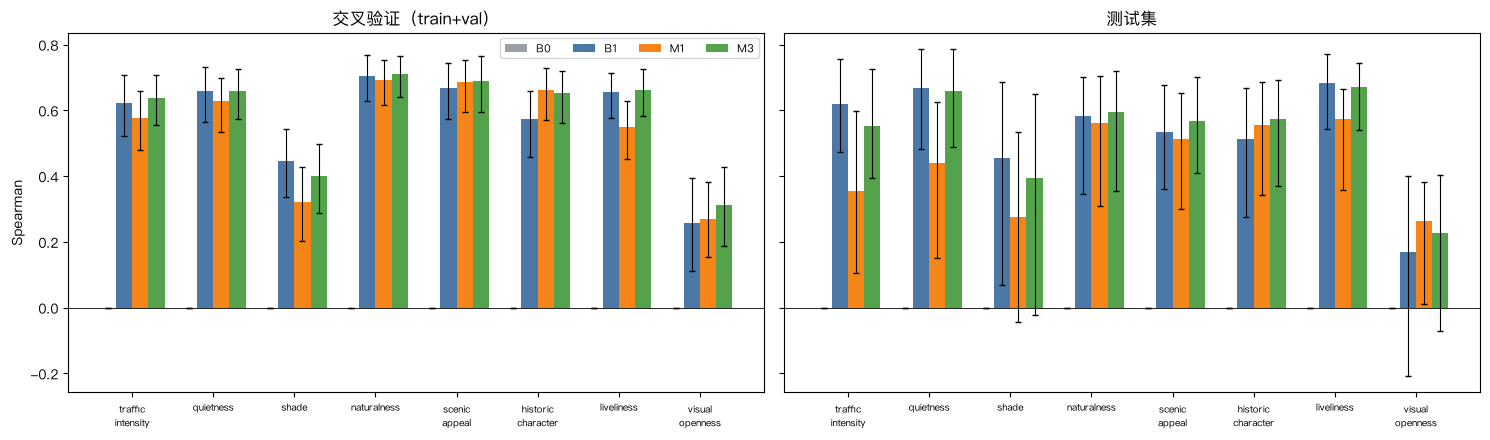

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
colors = {"B0": "#9aa0a6", "B1": "#4c78a8", "M1": "#f58518", "M3": "#54a24b"}
for ax, split, title in [(axes[0], "cv", "交叉验证（train+val）"), (axes[1], "test", "测试集")]:
    w = 0.2
    for i, m in enumerate(MODELS):
        r = R[(R.split == split) & (R.model == m)].set_index("dim").reindex(DIMS)
        x = np.arange(len(DIMS)) + (i - 1.5) * w
        ax.bar(x, r.spearman, w, label=m, color=colors[m],
               yerr=[(r.spearman - r.ci_lo).clip(lower=0), (r.ci_hi - r.spearman).clip(lower=0)], capsize=2, error_kw=dict(lw=.8))
    ax.set_xticks(range(len(DIMS))); ax.set_xticklabels([d.replace("_", "\n") for d in DIMS], fontsize=7)
    ax.axhline(0, c="k", lw=.6); ax.set_title(title); ax.set_ylabel("Spearman" if split == "cv" else "")
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 12. 保存结果、预测和实验日志

In [14]:
out_dir = f"results/{run_id}"
makedirs(path("results")); makedirs(path(out_dir))
write_parquet(R, path(out_dir, "metrics.parquet"))
write_parquet(DIFF, path(out_dir, "comparisons.parquet"))
allp = path("results", "metrics.parquet")
write_parquet(pd.concat([read_parquet(allp), R], ignore_index=True) if fs.exists(allp) else R, allp)

cv_df = pd.DataFrame({"cell_id": ds.cell_id.values[pool], "split": "cv", **{f"{m}__{d}": PRED_CV[m][:, j] for m in MODELS for j, d in enumerate(DIMS)}})
te_df = pd.DataFrame({"cell_id": ds.cell_id.values[test], "split": "test", **{f"{m}__{d}": PRED_TE[m][:, j] for m in MODELS for j, d in enumerate(DIMS)}})
write_parquet(pd.concat([cv_df, te_df], ignore_index=True), path(out_dir, "predictions.parquet"))

config = {"run_id": run_id, "dataset_version": DATASET_VERSION, "backbones": BACKBONES, "tta": TTA, "embedding_meta": EMB_META,
          "chosen": {k: v for k, v in CHOSEN.items()}, "ridge_alphas": RIDGE_ALPHAS, "pca_dims": PCA_DIMS,
          "lgb_base": LGB_BASE, "lgb_grid": LGB_GRID, "n_boot": N_BOOT, "seed": SEED,
          "n_pool": int(len(pool)), "n_test": int(len(test)),
          "versions": {"lightgbm": lgb.__version__},
          "label_validation": "pending (E1)"}
with fs.open(path(out_dir, "config.json"), "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False, default=str)

# ---- 实验日志（追加到项目目录里的 docs/EXPERIMENTS.md）----
te = R[R.split == "test"]
mean_te = {m: te[te.model == m].spearman.mean() for m in MODELS}
d_m3 = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M3 − B1")]
d_m1 = DIFF[(DIFF.split == "test") & (DIFF.comparison == "M1 − B1")]
weak = te[te.model == "M3"].sort_values("spearman").query("spearman < 0.3").dim.tolist()
good = te[te.model == "M3"].sort_values("spearman", ascending=False).query("spearman >= 0.5").dim.tolist()
concl = [f"- 最佳编码器（CV）：**{BEST_BB}**；M3 的 PCA 维度：{CHOSEN['M3']['pca']}；LightGBM 参数：{CHOSEN['B1']}。",
         f"- 测试集平均 Spearman：B0 {mean_te['B0']:.2f} · B1 {mean_te['B1']:.2f} · M1 {mean_te['M1']:.2f} · M3 {mean_te['M3']:.2f}。",
         f"- M3 相对 B1：{int(d_m3.better.sum())}/8 个维度显著更好（CI 不含 0），{int(d_m3.worse.sum())}/8 个显著更差，平均差 {d_m3['diff'].mean():+.3f}。",
         f"- M1（只看卫星图）相对 B1：{int(d_m1.better.sum())}/8 个显著更好，{int(d_m1.worse.sum())}/8 个显著更差，平均差 {d_m1['diff'].mean():+.3f}。",
         f"- 较可预测的维度（M3 测试 Spearman ≥ 0.5）：{', '.join(good) or '无'}；较弱的维度（< 0.3）：{', '.join(weak) or '无'}。"]
nxt = []
better_dims = d_m3[d_m3.better].dim.tolist()
if len(better_dims) >= 3 and d_m3["diff"].mean() > 0:
    nxt.append(f"融合模型在 {len(better_dims)} 个维度上显著超过 OSM 基线（{', '.join(better_dims)}）：下一步尝试端到端微调（M2），并对比遥感专用编码器（SatlasPretrain）。")
elif better_dims:
    nxt.append(f"融合模型只在个别维度上显著超过 OSM 基线（{', '.join(better_dims)}），整体平均差 {d_m3['diff'].mean():+.3f}：卫星图的增量价值有限。先做 E1 确认标签可靠，再试遥感专用编码器和微调（M2）。")
else:
    nxt.append("卫星图特征没有显著超过 OSM 基线：先检查标签质量（E1）和编码器是否合适，再试遥感专用编码器（SatlasPretrain）和微调（M2）。")
if weak:
    nxt.append(f"弱维度（{', '.join(weak)}）：回到 E1，看是标签不可靠，还是俯视图本来就推断不了；不可靠的维度考虑删除或重写打分规则。")
nxt += ["做 E1 人工标注，只对通过的维度下结论。", "扩大数据：放宽冬季过滤的消融实验；加入第二座城市做真正的跨城测试。"]

section = f"""
## {run_id}

- **日期**：{now_iso()} · **数据集**：{DATASET_VERSION}（{len(pool)} 个训练 / 验证格子，{len(test)} 个测试格子）· TTA：{TTA}
- **目的**：回答"只看卫星图能不能预测骑行体验？卫星图有没有提供 OSM 之外的信息？"
- **标签**：Gemini 生成，**尚未经人工验证（E1）**。以下所有"准确"都是相对 Gemini 打分而言。

### 测试集结果（Spearman [95% CI]，按区块自助法）

{table('test').to_markdown()}

### 结论
{chr(10).join(concl)}

### 下一轮计划
{chr(10).join('- ' + x for x in nxt)}

### 备注（人工填写）
- 
"""
if STORAGE == "local":
    os.makedirs("docs", exist_ok=True)
    with open("docs/EXPERIMENTS.md", "a", encoding="utf-8") as f:
        if os.path.getsize("docs/EXPERIMENTS.md") == 0 if os.path.exists("docs/EXPERIMENTS.md") else True:
            f.write("# GreenPath 实验日志\n\n每次运行 `07_baselines.ipynb` 会追加一节。\n")
        f.write(section)
    print("已追加到 docs/EXPERIMENTS.md")
print("\n".join(concl))

已追加到 docs/EXPERIMENTS.md
- 最佳编码器（CV）：**clip_b16**；M3 的 PCA 维度：32；LightGBM 参数：{'n_estimators': 150, 'num_leaves': 7}。
- 测试集平均 Spearman：B0 0.00 · B1 0.53 · M1 0.44 · M3 0.53。
- M3 相对 B1：0/8 个维度显著更好（CI 不含 0），0/8 个显著更差，平均差 +0.002。
- M1（只看卫星图）相对 B1：0/8 个显著更好，4/8 个显著更差，平均差 -0.086。
- 较可预测的维度（M3 测试 Spearman ≥ 0.5）：liveliness, quietness, naturalness, historic_character, scenic_appeal, traffic_intensity；较弱的维度（< 0.3）：visual_openness。


## 13. 运行记录

In [15]:
write_manifest({"step": "07_baselines", "run_id": run_id, "dataset_version": DATASET_VERSION,
                "chosen": {k: str(v) for k, v in CHOSEN.items()},
                "test_mean_spearman": {m: round(float(mean_te[m]), 4) for m in MODELS},
                "outputs": [out_dir, "results/metrics.parquet", "docs/EXPERIMENTS.md"],
                "finished_at": now_iso()}, "07_baselines_manifest.json")
print("完成：", out_dir)

完成： results/baselines-first-run-20261013T0159


## 下一步
- **E1**：用 `processed/qa/` 里的人工标注表验证标签，决定哪些维度可信。
- **M2（微调）**：编码器和回归头一起训练（分层学习率、带掩码的 MSE、按验证集 Spearman 早停），用 Vertex AI 的 GPU 或 Mac 的 MPS。
- 遥感专用编码器（SatlasPretrain）、第二座城市（Providence）做跨城测试。
- 容器化：把 01–06 搬进 Docker，`docker compose up` 一条命令跑完。